# 01 · EDA de las variables del modelo

**Bloque del objetivo.** La pregunta del TFM es cómo ha cambiado entre 2012 y 2022 la relación del esfuerzo del alumno y de los recursos de que dispone con su nota de matemáticas, según el perfil de su centro. El modelo es una regresión por edición (con efecto fijo de país) y un XGBoost, sobre los alumnos de cada perfil de centro. Este notebook prepara esa comparación:

* ¿Qué alumnos y países entran en el análisis, y cuántos centros tiene cada perfil? (sección 1)
* ¿Cómo se mide el esfuerzo en cada edición? (sección 2)
* ¿Qué falta de cada variable, y qué preguntas no se hicieron? (sección 3)
* ¿Son distintos los alumnos sin dato, en general y según el perfil de su centro? (secciones 4 y 5)

Las variables, por su papel (`VARIABLES_MODELO` en `src/tabla_alumno.py`), son:

* **De interés**: el esfuerzo, medido con las horas diarias de deberes (`tiempo_deberes_totales_diarios`), el absentismo (`SKIPPING`) y la impuntualidad (`TARDYSD`), por separado, y los recursos de estudio del hogar (`recursos_estudio`, de `01_EDA_recursos_alumno`).
* **Controles**: origen social del alumno (ocupación y educación de los padres, riqueza del hogar y libros en casa), sexo, inmigración y composición social del centro (media en el centro de la ocupación y la educación de los padres, sin las posesiones del hogar, de las que salen los recursos de estudio).
* **Comprobación**: el `ESCS` medio del centro, en lugar de la composición social.

Los huecos se tratan según el papel de la variable: las variables de interés no se imputan (cada estimación usa los alumnos que la tienen); en los controles se añade un indicador de «sin dato»; y si una pregunta no se hizo en un país-edición, ese país-edición queda fuera de lo que use esa variable. Las convenciones de pesos y valores plausibles están en `00_pipeline_multiedicion_PISA`.

## 0. Configuración

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.pisa_estadisticas import centrar_en_grupos
from src.pisa_pipeline import columnas_pv, rutas_datos_anuales
from src.tabla_alumno import CLAVES_ALUMNO, VARIABLES_MODELO, paises_edicion_sin_variable, tabla_por_alumno

pd.set_option('display.width', 200)

EDICIONES = [2012, 2015, 2018, 2022]
RUTA_RAW_BASE = '../../data/raw'
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_REPORTS = '../../reports'
ASIGNATURAS = {'matemáticas': 'MATH', 'lectura': 'READ', 'ciencias': 'SCIE'}
VARIABLES = [variable for grupo in VARIABLES_MODELO.values() for variable in grupo]
DE_INTERES = VARIABLES_MODELO['esfuerzo'] + VARIABLES_MODELO['recursos del alumno']
EJES_PERFIL = ['titularidad', 'ubicacion', 'tamaño']
MINIMO_CENTROS = 30      # centros de un perfil-edición por debajo de los cuales sus resultados serían poco representativos
MINIMO_SIN_DATO = 100    # alumnos sin dato de un grupo-edición por debajo de los cuales no se da su diferencia de nota


def media_ponderada(valores, pesos):
    """Media de `valores` ponderada con `pesos`, sin contar los vacíos."""
    con_dato = valores.notna()
    return np.average(valores[con_dato], weights=pesos[con_dato]) if con_dato.any() else np.nan


# Una fila por alumno con perfil de centro, de los países con perfil en las cuatro ediciones
datos = tabla_por_alumno(RUTA_RAW_BASE, RUTA_INTERMEDIOS, EDICIONES)
datos[EJES_PERFIL] = datos['perfil'].str.split('_', expand=True)
print(f"{len(datos)} alumnos de {datos['CNT'].nunique()} países")
datos.groupby('year').agg(alumnos=('CNTSTUID', 'size'), centros=('centro', 'nunique')).T

736382 alumnos de 25 países


year,2012,2015,2018,2022
alumnos,215192,151622,183474,186094
centros,8699,5871,7186,6987


## 1. Alumnos y países del análisis

El perfil de centro (`00_Pipeline_generacion_estratos`) combina titularidad (`PUB` público, `CON` concertado, `PRI` privado), ubicación (`RUR` rural, `URB` urbano) y tamaño (`PEQ` pequeño, `MED` mediano, `MACRO` grande): 18 perfiles. Solo entran los alumnos cuyo centro tiene perfil y, de ellos, los de los países con perfil en las cuatro ediciones, para que el cambio entre ediciones no se mezcle con un cambio de países. El primer gráfico muestra el % de alumnos de cada país-edición con perfil; el segundo, los centros de cada perfil-edición en los países del análisis.

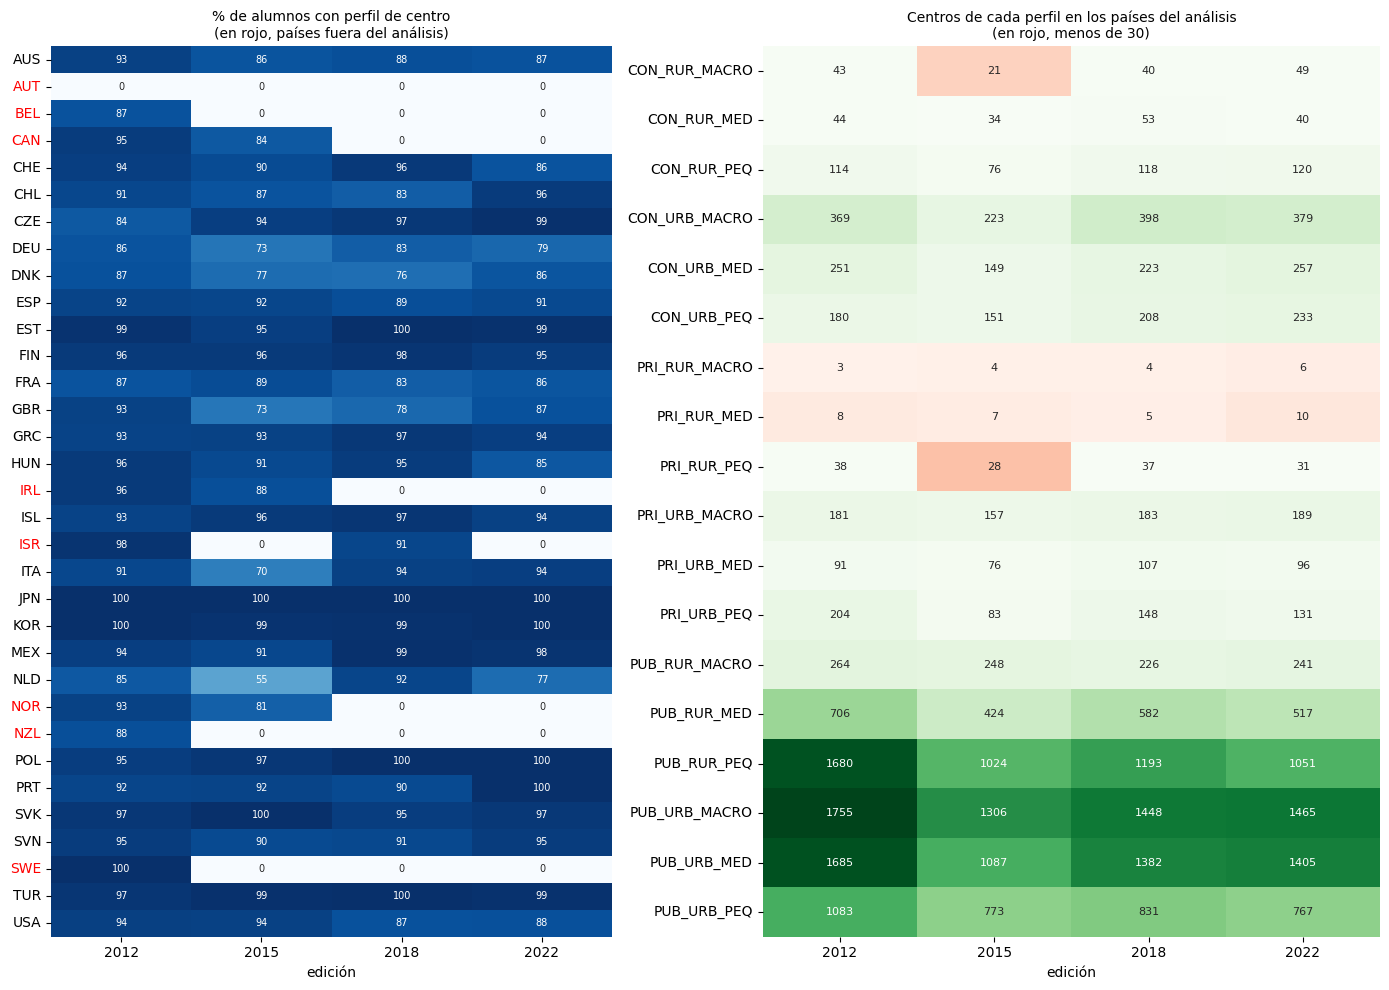

Países fuera del análisis, con las ediciones en las que no tienen ningún alumno con perfil:
{'AUT': [2012, 2015, 2018, 2022], 'BEL': [2015, 2018, 2022], 'CAN': [2018, 2022], 'IRL': [2018, 2022], 'ISR': [2015, 2022], 'NOR': [2018, 2022], 'NZL': [2015, 2018, 2022], 'SWE': [2015, 2018, 2022]}
Perfiles con menos de 30 centros en alguna edición: CON_RUR_MACRO (mínimo 21), PRI_RUR_MACRO (mínimo 3), PRI_RUR_MED (mínimo 5), PRI_RUR_PEQ (mínimo 28)


In [2]:
alumnos_por_pais = pd.concat([pd.read_parquet(rutas_datos_anuales(RUTA_RAW_BASE, edicion)[0], columns=['CNT']).astype(str).assign(year=edicion)
                              for edicion in EDICIONES])
con_perfil = pd.concat([pd.read_parquet(os.path.join(RUTA_INTERMEDIOS, 'estratos_fijos', f'pisa{edicion}_estratos_fijos.parquet'), columns=['CNT']).astype(str).assign(year=edicion)
                        for edicion in EDICIONES])
porcentaje_con_perfil = (100 * con_perfil.groupby(['CNT', 'year']).size() / alumnos_por_pais.groupby(['CNT', 'year']).size()).fillna(0).unstack('year')
paises_analisis = set(datos['CNT'])

centros_perfil = datos.groupby(['perfil', 'year'])['centro'].nunique().unstack('year').fillna(0).astype(int)
fig, ejes = plt.subplots(1, 2, figsize=(14, 10), gridspec_kw={'width_ratios': [1, 1.1]})
sns.heatmap(porcentaje_con_perfil, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar=False, ax=ejes[0], annot_kws={'fontsize': 7})
for etiqueta in ejes[0].get_yticklabels():
    etiqueta.set_color('black' if etiqueta.get_text() in paises_analisis else 'red')
ejes[0].set_title('% de alumnos con perfil de centro\n(en rojo, países fuera del análisis)', fontsize=10)
sns.heatmap(centros_perfil, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ejes[1], annot_kws={'fontsize': 8},
            mask=centros_perfil < MINIMO_CENTROS)
sns.heatmap(centros_perfil, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ejes[1], annot_kws={'fontsize': 8},
            mask=centros_perfil >= MINIMO_CENTROS, vmin=0, vmax=4 * MINIMO_CENTROS)
ejes[1].set_title(f'Centros de cada perfil en los países del análisis\n(en rojo, menos de {MINIMO_CENTROS})', fontsize=10)
for eje in ejes:
    eje.set_xlabel('edición')
    eje.set_ylabel('')
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_variables_modelo_universo.png', dpi=300, bbox_inches='tight')
plt.show()

fuera = porcentaje_con_perfil[~porcentaje_con_perfil.index.isin(paises_analisis)]
print('Países fuera del análisis, con las ediciones en las que no tienen ningún alumno con perfil:')
print({pais: [edicion for edicion in EDICIONES if fila[edicion] == 0] for pais, fila in fuera.iterrows()})
pocos = centros_perfil[(centros_perfil < MINIMO_CENTROS).any(axis=1)]
print(f'Perfiles con menos de {MINIMO_CENTROS} centros en alguna edición:', ', '.join(f'{perfil} (mínimo {fila.min()})' for perfil, fila in pocos.iterrows()))

**Qué se ve.**

* Entran 736.382 alumnos de 25 países: de 151.622 (2015) a 215.192 (2012) por edición, en 5.871 a 8.699 centros.
* **Ocho países quedan fuera** porque en alguna edición ningún alumno tiene perfil (PISA no publica la titularidad, la ubicación o el tamaño de sus centros): Austria en todas las ediciones; Bélgica, Nueva Zelanda y Suecia desde 2015; Canadá, Irlanda y Noruega en 2018 y 2022, e Israel en 2015 y 2022. En los 25 países que quedan, tienen perfil entre el 55 % (Países Bajos en 2015) y el 100 % de los alumnos.
* **Perfiles pequeños**: cuatro tienen menos de 30 centros en alguna edición: privado rural grande (`PRI_RUR_MACRO`, de 3 a 6 centros), privado rural mediano (`PRI_RUR_MED`, de 5 a 10), concertado rural grande (`CON_RUR_MACRO`, 21 en 2015) y privado rural pequeño (`PRI_RUR_PEQ`, 28 en 2015). Los dos primeros no llegan a 30 en ninguna edición; sus resultados no serán representativos.

## 2. Cómo se mide el esfuerzo en cada edición

**Horas de deberes** (`pisa_esfuerzo_alumno_anual.parquet`, del EDA del esfuerzo del alumno, en horas al día y con un máximo de 4,5). La pregunta cambia en cada edición, según los codebooks de PISA:

* **2012**: horas a la semana de las preguntas `ST57Q01`, `ST57Q02` y `ST57Q05`, divididas entre 5.
* **2015**: horas a la semana de «aprendizaje adicional» en ciencias, matemáticas y lengua (`ST071Q01NA` a `ST071Q03NA`), divididas entre 5.
* **2018**: cuánto estudió el alumno al salir del colegio el último día que fue a clase (`EC159`), de un cuestionario opcional.
* **2022**: tiempo total de deberes al día, en seis tramos (`ST296Q04JA`, de «hasta 30 minutos» a «más de 4 horas»), convertidos al punto medio de cada tramo.

Como no miden lo mismo, las horas no se comparan entre ediciones: el modelo compara a cada alumno con los de su edición (por tramos de horas dentro de cada edición) y lo que se compara entre ediciones es la diferencia entre perfiles.

**Absentismo e impuntualidad**: la OCDE publica `SKIPPING` (ha faltado un día entero o se ha saltado alguna clase en las dos últimas semanas) y `TARDYSD` (ha llegado tarde: nunca, una o dos veces, tres o más) solo en 2022, pero sus ítems están en las cuatro ediciones con la misma escala. `construir_skipping` y `construir_tardysd` (`src/tabla_alumno.py`) aplican la regla de la OCDE en todas las ediciones; aquí se comprueba que en 2022 dan lo mismo que los índices oficiales, y se describe cada medida por edición (ponderada con `SENWT`).

In [3]:
oficiales = pd.read_parquet(rutas_datos_anuales(RUTA_RAW_BASE, 2022)[0], columns=CLAVES_ALUMNO + ['SKIPPING', 'TARDYSD']).astype({clave: str for clave in CLAVES_ALUMNO})
comparacion = datos[datos['year'] == 2022].merge(oficiales, on=CLAVES_ALUMNO, suffixes=('', '_ocde'), validate='one_to_one')
for indice in ['SKIPPING', 'TARDYSD']:
    ambos = comparacion[[indice, f'{indice}_ocde']].dropna()
    print(f"{indice} en 2022: igual al oficial en el {100 * (ambos[indice] == ambos[f'{indice}_ocde']).mean():.2f} % de {len(ambos)} alumnos; "
          f"vacío en {comparacion[indice].isna().sum()} alumnos (el oficial, en {comparacion[f'{indice}_ocde'].isna().sum()})")

descripcion = {}
for edicion, grupo in datos.groupby('year'):
    descripcion[edicion] = {
        'horas de deberes al día (media)': media_ponderada(grupo['tiempo_deberes_totales_diarios'], grupo['SENWT']),
        '% con 0 horas': 100 * media_ponderada((grupo['tiempo_deberes_totales_diarios'] == 0).where(grupo['tiempo_deberes_totales_diarios'].notna()).astype(float), grupo['SENWT']),
        '% con 4,5 horas (máximo)': 100 * media_ponderada((grupo['tiempo_deberes_totales_diarios'] >= 4.5).where(grupo['tiempo_deberes_totales_diarios'].notna()).astype(float), grupo['SENWT']),
        '% con absentismo': 100 * media_ponderada(grupo['SKIPPING'], grupo['SENWT']),
        '% que llega tarde alguna vez': 100 * media_ponderada((grupo['TARDYSD'] >= 1).where(grupo['TARDYSD'].notna()).astype(float), grupo['SENWT']),
        '% que llega tarde tres o más veces': 100 * media_ponderada((grupo['TARDYSD'] == 2).where(grupo['TARDYSD'].notna()).astype(float), grupo['SENWT']),
    }
pd.DataFrame(descripcion).round(2)

SKIPPING en 2022: igual al oficial en el 100.00 % de 178846 alumnos; vacío en 7248 alumnos (el oficial, en 7248)
TARDYSD en 2022: igual al oficial en el 100.00 % de 178324 alumnos; vacío en 7770 alumnos (el oficial, en 7770)


,2012,2015,2018,2022
horas de deberes al día (media),1.33,2.00,1.86,1.52
% con 0 horas,4.44,2.81,17.53,0.00
"% con 4,5 horas (máximo)",3.55,11.01,10.37,5.99
% con absentismo,26.02,34.94,32.33,29.52
% que llega tarde alguna vez,34.75,42.88,45.64,43.47
% que llega tarde tres o más veces,9.75,14.48,17.15,15.52


**Qué se ve.**

* **La regla de la OCDE se reproduce**: en 2022, el absentismo y la impuntualidad construidos coinciden con los oficiales en el 100 % de los alumnos y tienen los mismos vacíos, así que se pueden usar en 2012-2018.
* **Horas de deberes**: la media va de 1,33 horas al día (2012) a 2,00 (2015), pero buena parte de la diferencia es de la pregunta. En 2018 el 17,53 % dice 0 horas (el último día no estudió), mientras que en 2022 nadie puede decir 0 (el primer tramo es «hasta 30 minutos»); el máximo de 4,5 horas lo alcanzan del 3,55 % (2012) al 11,01 % (2015) de los alumnos. Por eso las horas se comparan por tramos dentro de cada edición.
* **Absentismo e impuntualidad**: entre el 26,02 % y el 34,94 % de los alumnos ha faltado un día o a alguna clase en las dos últimas semanas, y entre el 34,75 % y el 45,64 % ha llegado tarde alguna vez (entre el 9,75 % y el 17,15 %, tres o más veces). La pregunta es la misma en todas las ediciones.

## 3. Alumnos sin dato y preguntas que no se hicieron

Para cada variable, el % de alumnos sin dato en cada edición (sin ponderar) y cuántos países-edición no hicieron la pregunta (`paises_edicion_sin_variable`: la variable falta en todos sus alumnos), con la lista de esos países-edición.

In [4]:
sin_pregunta = paises_edicion_sin_variable(datos, VARIABLES)
pais_edicion = pd.Series(list(zip(datos['CNT'], datos['year'])), index=datos.index)
resumen_nulos = datos[VARIABLES].isna().groupby(datos['year']).mean().mul(100).T
resumen_nulos.columns = [f'% sin dato {edicion}' for edicion in resumen_nulos.columns]
resumen_nulos['países-edición sin la pregunta'] = [len(sin_pregunta[variable]) for variable in VARIABLES]
display(resumen_nulos.round(1))
for variable in VARIABLES:
    if sin_pregunta[variable]:
        print(f'{variable}:', ', '.join(f'{pais} {edicion}' for pais, edicion in sorted(sin_pregunta[variable], key=lambda par: (par[1], par[0]))))
paises_deberes_2018 = sorted(set(datos.loc[(datos['year'] == 2018) & datos['tiempo_deberes_totales_diarios'].notna(), 'CNT']))
print(f'Países con horas de deberes en 2018 ({len(paises_deberes_2018)}):', ', '.join(paises_deberes_2018))

,% sin dato 2012,% sin dato 2015,% sin dato 2018,% sin dato 2022,países-edición sin la pregunta
tiempo_deberes_totales_diarios,35.6,10.2,55.8,8.4,13
SKIPPING,1.1,3.3,18.2,3.9,0
TARDYSD,1.4,3.7,18.5,4.2,0
recursos_estudio,2.1,2.4,3.2,13.7,0
HISEI_TREND,3.1,6.4,7.8,9.7,0
PAREDINT_TREND,3.6,3.4,4.4,4.4,0
riqueza_hogar,2.4,4.7,7.1,3.4,0
libros,2.3,2.1,3.1,2.8,0
chica,0.0,0.0,0.0,0.0,0
inmigrante,2.7,2.9,7.4,7.9,2


tiempo_deberes_totales_diarios: CHE 2018, CHL 2018, CZE 2018, DEU 2018, EST 2018, FIN 2018, FRA 2018, JPN 2018, MEX 2018, NLD 2018, PRT 2018, TUR 2018, USA 2018
inmigrante: JPN 2018, JPN 2022
Países con horas de deberes en 2018 (12): AUS, DNK, ESP, GBR, GRC, HUN, ISL, ITA, KOR, POL, SVK, SVN


**Qué se ve.**

* **Horas de deberes**: faltan al 35,6 % de los alumnos en 2012 (la pregunta estaba en una forma rotada del cuestionario), al 10,2 % en 2015, al 55,8 % en 2018 y al 8,4 % en 2022. En 2018 solo 12 de los 25 países hicieron la pregunta (AUS, DNK, ESP, GBR, GRC, HUN, ISL, ITA, KOR, POL, SVK y SVN): son los únicos con horas de deberes en las cuatro ediciones.
* **Absentismo e impuntualidad**: faltan poco (del 1,1 % al 4,2 %) salvo en 2018 (18,2 % y 18,5 %); todos los países hicieron la pregunta.
* **Recursos de estudio**: faltan al 2,1-3,2 % hasta 2018 y al 13,7 % en 2022, por las preguntas de tipos de libros (`01_EDA_recursos_alumno`).
* **Controles**: la ocupación de los padres falta al 3,1-9,7 % de los alumnos, la riqueza del hogar al 2,4-7,1 % y la inmigración al 2,7-7,9 % (Japón no la pregunta en 2018 ni en 2022); el resto, como mucho al 4,4 %. La composición social y el `ESCS` medio del centro faltan como mucho al 0,3 %.

## 4. ¿Son distintos los alumnos sin dato?

Si los alumnos sin dato son distintos, la relación que mida el modelo vale para los que contestaron, no para todos. Para cada variable y edición, en los países-edición que hicieron la pregunta, se compara la nota de los alumnos sin dato con la de los que lo tienen, **relativa a la media de su país-edición** (media de sus valores plausibles, ponderada con `SENWT`), en las tres asignaturas. La diferencia (sin dato − con dato) queda vacía si hay menos de 100 alumnos sin dato.

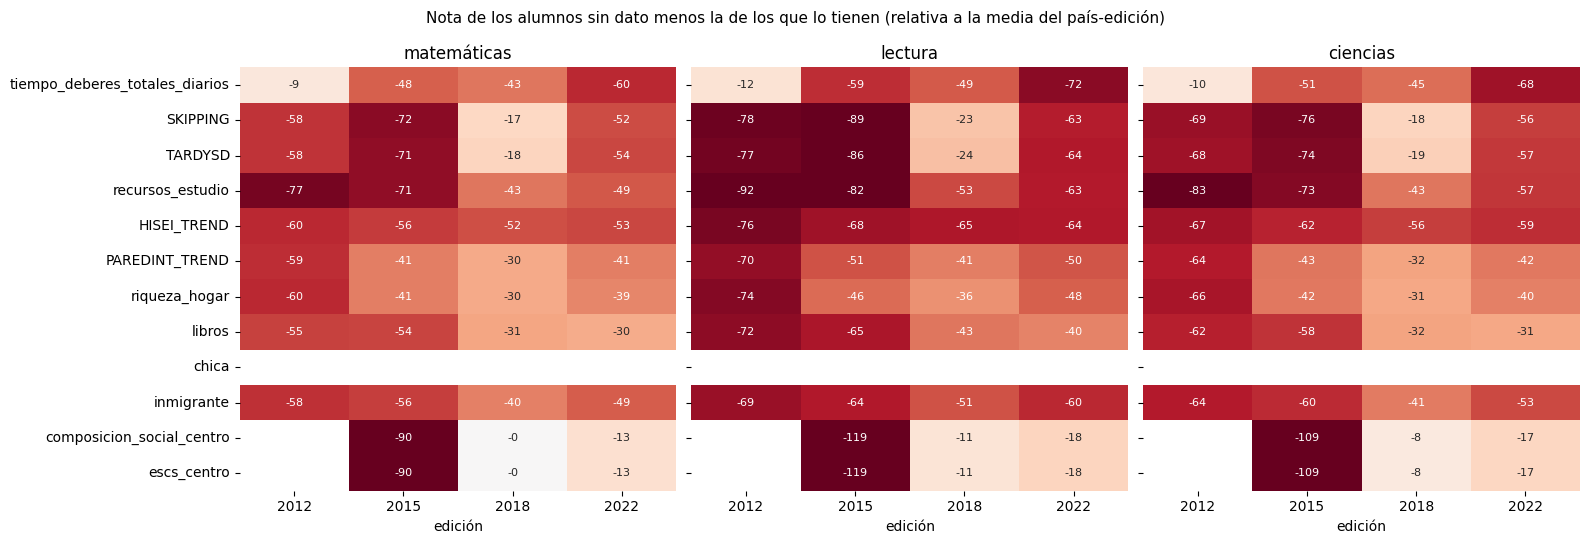

asignatura                     ciencias                    lectura                    matemáticas                  
edición                            2012   2015  2018  2022    2012   2015  2018  2022        2012  2015  2018  2022
variable                                                                                                           
tiempo_deberes_totales_diarios     -9.9  -50.6 -44.8 -67.9   -11.6  -59.1 -48.9 -72.3        -9.1 -47.6 -42.5 -60.4
SKIPPING                          -69.1  -75.7 -18.1 -55.6   -78.4  -89.4 -23.0 -63.0       -58.1 -72.0 -16.5 -52.5
TARDYSD                           -67.8  -74.5 -19.0 -56.5   -76.9  -86.2 -24.1 -64.1       -58.0 -70.8 -17.7 -53.6
recursos_estudio                  -82.7  -73.4 -42.7 -57.2   -91.8  -82.4 -53.0 -63.2       -76.7 -71.1 -42.7 -49.5
HISEI_TREND                       -66.9  -61.5 -55.6 -58.8   -75.7  -67.7 -64.7 -64.2       -60.3 -55.8 -51.9 -53.4
PAREDINT_TREND                    -63.5  -42.8 -32.0 -42.1   -70.5  -50.8 -40.7 -50.2       -58.8 -40.8 -30.3 -40.8
riqueza_hogar                     -66.1  -42.5 -30.8 -40.4   -73.5  -45.6 -36.3 -47.6       -60.4 -40.9 -30.4 -39.3
libros                            -62.1  -58.1 -32.3 -30.6   -71.6  -65.1 -42.8 -39.5       -54.5 -53.9 -31.4 -29.7
chica                               NaN    NaN   NaN   NaN     NaN    NaN   NaN   NaN         NaN   NaN   NaN   NaN
inmigrante                        -63.5  -59.9 -41.5 -52.5   -68.9  -63.8 -51.1 -60.2       -58.2 -55.6 -40.0 -48.7
composicion_social_centro           NaN -108.9  -7.6 -17.1     NaN -119.3 -10.9 -17.9         NaN -90.1  -0.4 -12.8
escs_centro                         NaN -108.9  -7.6 -17.1     NaN -119.3 -10.9 -17.9         NaN -90.1  -0.4 -12.8

In [5]:
for asignatura, dominio in ASIGNATURAS.items():
    nota = datos[columnas_pv(dominio)].mean(axis=1)   # en 2012, media de sus 5 valores plausibles
    datos[f'nota_relativa_{asignatura}'] = centrar_en_grupos(datos.assign(nota=nota), ['nota'], ['pais_edicion'], peso_col='SENWT')['nota']


def diferencia_sin_dato(grupo, variable, asignatura='matemáticas'):
    """% de alumnos sin `variable`, cuántos son y su nota relativa media (con SENWT) menos la de los que la tienen
    (vacía con menos de `MINIMO_SIN_DATO` alumnos sin dato)."""
    hueco = grupo[variable].isna()
    nota = grupo[f'nota_relativa_{asignatura}']
    diferencia = (media_ponderada(nota[hueco], grupo['SENWT'][hueco]) - media_ponderada(nota[~hueco], grupo['SENWT'][~hueco])
                  if hueco.sum() >= MINIMO_SIN_DATO else np.nan)
    return pd.Series({'% sin dato': 100 * hueco.mean(), 'alumnos sin dato': hueco.sum(), 'diferencia': diferencia})


filas = []
for variable in VARIABLES:
    preguntada = datos[~pais_edicion.isin(sin_pregunta[variable])]
    for edicion, grupo in preguntada.groupby('year'):
        for asignatura in ASIGNATURAS:
            filas.append({'variable': variable, 'edición': edicion, 'asignatura': asignatura, **diferencia_sin_dato(grupo, variable, asignatura)})
huecos = pd.DataFrame(filas)
diferencias = huecos.pivot_table(index='variable', columns=['asignatura', 'edición'], values='diferencia').reindex(VARIABLES)

fig, ejes = plt.subplots(1, len(ASIGNATURAS), figsize=(16, 5.5), sharey=True)
for eje, asignatura in zip(ejes, ASIGNATURAS):
    sns.heatmap(diferencias[asignatura], annot=True, fmt='.0f', cmap='RdBu', center=0, vmin=-80, vmax=80, cbar=False, ax=eje, annot_kws={'fontsize': 8})
    eje.set_title(asignatura)
    eje.set_ylabel('')
fig.suptitle('Nota de los alumnos sin dato menos la de los que lo tienen (relativa a la media del país-edición)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_variables_modelo_huecos.png', dpi=300, bbox_inches='tight')
plt.show()
diferencias.round(1)

**Qué se ve.**

* En todas las variables, los alumnos sin dato sacan menos nota que los que lo tienen dentro de su país-edición, y la diferencia es algo mayor en lectura que en matemáticas y ciencias.
* **Horas de deberes**: en 2012 la diferencia es pequeña (−9,1 puntos en matemáticas), porque el hueco viene de la rotación del cuestionario; en 2015, 2018 y 2022 es de −47,6, −42,5 y −60,4 puntos.
* **Absentismo e impuntualidad**: entre −52,5 y −72,0 puntos en matemáticas, salvo en 2018 (−16,5 y −17,7): ese año faltan a más alumnos (18,2 % y 18,5 %) y se parecen más a los que contestan.
* **Recursos de estudio**: de −76,7 puntos en matemáticas (2012) a −42,7 (2018); en 2022, con el 13,7 % sin dato, −49,5.
* **Controles del alumno**: entre −29,7 y −60,4 puntos en matemáticas.
* **Composición social y `ESCS` medio del centro**: faltan como mucho al 0,3 % de los alumnos, así que sus diferencias (de −0,4 a −90,1 puntos en matemáticas) apenas pesan.

**Consecuencia para el modelo**: la relación que se mida con cada variable de interés vale para los alumnos que contestaron, que sacan más nota que la media de su país. No se imputa, porque la variable de interés imputada dependería del modelo de imputación; este límite se cuenta al presentar los resultados.

## 5. Alumnos sin dato por perfil de centro

Si unos perfiles pierden más alumnos sin dato que otros, o alumnos más flojos, la comparación entre perfiles se mezcla con quién contesta. Se repite la comparación anterior en matemáticas para las variables de interés, por cada eje del perfil (titularidad, ubicación y tamaño; tablas) y por perfil (gráfico).

**tiempo_deberes_totales_diarios**: % sin dato y diferencia de nota en matemáticas (sin dato − con dato), por eje del perfil

% sin dato                  diferencia                  
year                    2012  2015  2018 2022       2012  2015  2018  2022
eje         grupo                                                         
titularidad CON         35.2   9.5  21.5  9.5       -9.9 -52.4 -34.4 -47.0
            PRI         34.9   7.5  24.9  6.4       -3.4 -56.5 -39.5 -39.1
            PUB         35.7  10.5  27.6  8.3       -9.2 -46.0 -43.5 -64.6
ubicacion   RUR         36.1  10.5  29.7  9.8      -10.0 -40.3 -37.6 -55.0
            URB         35.4  10.1  24.9  7.9       -8.5 -50.4 -43.7 -61.1
tamaño      MACRO       34.9   8.7  30.5  8.1       -5.8 -44.4 -39.1 -56.5
            MED         35.8  10.5  25.8  7.6       -7.1 -41.8 -46.1 -56.9
            PEQ         36.3  11.9  22.1  9.8      -13.5 -51.3 -42.0 -62.6

**SKIPPING**: % sin dato y diferencia de nota en matemáticas (sin dato − con dato), por eje del perfil

% sin dato                 diferencia                  
year                    2012 2015  2018 2022       2012  2015  2018  2022
eje         grupo                                                        
titularidad CON          0.8  2.9  19.8  5.3      -63.2 -87.0 -26.6 -41.7
            PRI          0.8  1.6  16.9  3.1     -103.7 -59.3  -6.4 -29.1
            PUB          1.2  3.4  18.0  3.7      -54.5 -69.3 -15.0 -58.2
ubicacion   RUR          1.1  3.5  20.3  4.1      -51.5 -68.3 -13.9 -43.9
            URB          1.1  3.2  17.4  3.8      -60.8 -72.9 -15.8 -55.0
tamaño      MACRO        1.0  2.8  17.2  4.4      -49.9 -55.6  -9.0 -47.4
            MED          1.3  3.1  18.3  3.5      -55.0 -59.1 -14.6 -52.0
            PEQ          1.1  4.1  19.5  3.6      -68.9 -87.0 -22.8 -64.2

**TARDYSD**: % sin dato y diferencia de nota en matemáticas (sin dato − con dato), por eje del perfil

% sin dato                 diferencia                  
year                    2012 2015  2018 2022       2012  2015  2018  2022
eje         grupo                                                        
titularidad CON          1.1  3.3  20.1  5.4      -62.9 -83.7 -27.2 -41.7
            PRI          1.0  1.8  17.1  3.4      -99.7 -48.2  -7.8 -29.6
            PUB          1.4  3.9  18.4  4.0      -54.5 -68.6 -16.2 -59.2
ubicacion   RUR          1.4  4.0  20.7  4.7      -51.1 -68.9 -16.0 -50.0
            URB          1.3  3.6  17.7  4.0      -60.9 -70.7 -16.4 -54.0
tamaño      MACRO        1.2  3.2  17.4  4.6      -50.0 -54.8  -9.5 -47.5
            MED          1.5  3.6  18.6  3.8      -56.1 -59.4 -15.3 -52.6
            PEQ          1.4  4.5  19.9  4.1      -67.3 -84.8 -24.7 -64.9

**recursos_estudio**: % sin dato y diferencia de nota en matemáticas (sin dato − con dato), por eje del perfil

% sin dato                 diferencia                  
year                    2012 2015 2018  2022       2012  2015  2018  2022
eje         grupo                                                        
titularidad CON          1.5  1.5  2.9  14.1      -98.5 -73.6 -40.1 -42.7
            PRI          1.1  0.8  3.8  10.4     -108.8   NaN -12.3 -45.5
            PUB          2.3  2.6  3.1  13.9      -71.7 -69.1 -44.7 -50.6
ubicacion   RUR          2.6  2.5  3.1  16.0      -78.5 -72.9 -49.2 -45.2
            URB          1.9  2.3  3.2  13.0      -75.2 -69.9 -40.1 -49.6
tamaño      MACRO        1.8  2.2  3.6  13.0      -69.8 -67.2 -28.4 -50.4
            MED          2.1  2.4  2.9  13.6      -72.5 -63.6 -44.1 -44.5
            PEQ          2.5  2.5  2.9  15.1      -84.4 -79.1 -61.9 -50.0

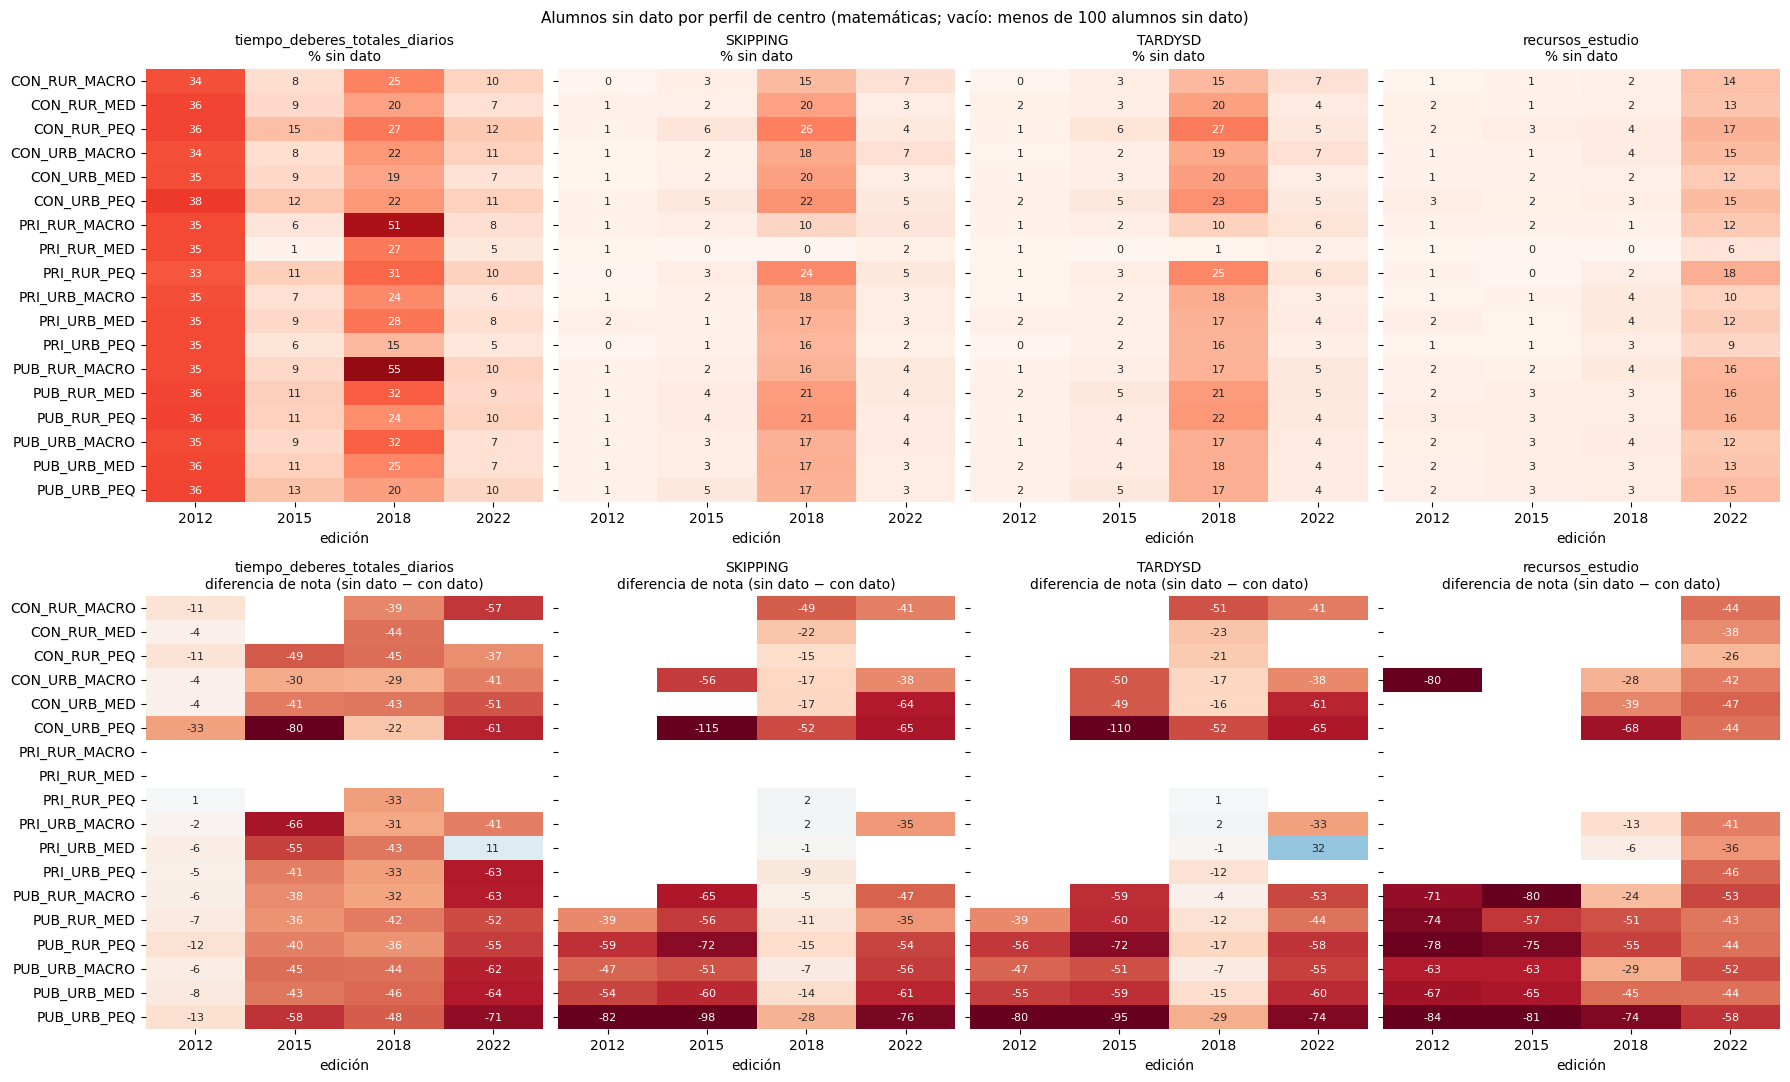

In [6]:
def tabla_huecos(datos_grupo, columna_grupo, variable):
    """% sin dato y diferencia de nota en matemáticas (sin dato − con dato) de cada grupo, por edición."""
    resumen = datos_grupo.groupby([columna_grupo, 'year']).apply(diferencia_sin_dato, variable, include_groups=False)
    return resumen[['% sin dato', 'diferencia']].unstack('year')


por_perfil = {}
for variable in DE_INTERES:
    preguntada = datos[~pais_edicion.isin(sin_pregunta[variable])]
    display(Markdown(f'**{variable}**: % sin dato y diferencia de nota en matemáticas (sin dato − con dato), por eje del perfil'))
    display(pd.concat({eje: tabla_huecos(preguntada, eje, variable) for eje in EJES_PERFIL}, names=['eje', 'grupo']).round(1))
    por_perfil[variable] = tabla_huecos(preguntada, 'perfil', variable)

fig, ejes = plt.subplots(2, len(DE_INTERES), figsize=(18, 11), sharey=True)
for columna_eje, variable in enumerate(DE_INTERES):
    sns.heatmap(por_perfil[variable]['% sin dato'], annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=60, cbar=False, ax=ejes[0, columna_eje], annot_kws={'fontsize': 8})
    sns.heatmap(por_perfil[variable]['diferencia'], annot=True, fmt='.0f', cmap='RdBu', center=0, vmin=-80, vmax=80, cbar=False, ax=ejes[1, columna_eje], annot_kws={'fontsize': 8})
    ejes[0, columna_eje].set_title(f'{variable}\n% sin dato', fontsize=10)
    ejes[1, columna_eje].set_title(f'{variable}\ndiferencia de nota (sin dato − con dato)', fontsize=10)
for eje in ejes.flat:
    eje.set_xlabel('edición')
    eje.set_ylabel('')
fig.suptitle('Alumnos sin dato por perfil de centro (matemáticas; vacío: menos de 100 alumnos sin dato)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_variables_modelo_huecos_perfil.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **El % de alumnos sin dato depende de la edición, no del perfil.** En las horas de deberes, entre grupos de un mismo eje va del 34,9 % al 36,3 % en 2012, del 7,5 % al 11,9 % en 2015, del 21,5 % al 30,5 % en 2018 y del 6,4 % al 9,8 % en 2022.
* **En 2022, los alumnos sin dato de los centros públicos son más flojos que los de los privados**: en las horas de deberes sacan 64,6 puntos menos que los que contestan en los públicos, 47,0 en los concertados y 39,1 en los privados; en el absentismo, 58,2, 41,7 y 29,1; en la impuntualidad, 59,2, 41,7 y 29,6. En los recursos de estudio no pasa (50,6, 42,7 y 45,5).
* **El orden entre grupos no se mantiene en todas las ediciones**: en los recursos de estudio de 2012, los concertados (−98,5) y los privados (−108,8) pierden alumnos más flojos que los públicos (−71,7), pero ese año faltan al 1,1-2,6 % de los alumnos.
* **Perfiles pequeños**: en el privado rural grande y el privado rural mediano no se puede medir la diferencia en ninguna variable ni edición (menos de 100 alumnos sin dato).

**Consecuencia para el modelo**: dentro de cada edición, todos los perfiles pierden una proporción parecida de alumnos, pero en 2022 los públicos pierden alumnos más flojos en las tres medidas del esfuerzo, así que la comparación entre públicos y privados de ese año se apoya en alumnos públicos más seleccionados. Es un límite que hay que contar.

## Hallazgos

* **Universo**: 736.382 alumnos con perfil de centro de 25 países. Ocho países (AUT, BEL, CAN, IRL, ISR, NOR, NZL, SWE) quedan fuera porque PISA no publica en alguna edición los datos que definen el perfil. El privado rural grande y el privado rural mediano tienen menos de 30 centros en todas las ediciones (como mucho 6 y 10).
* **Esfuerzo**: el absentismo y la impuntualidad se construyen con la regla de la OCDE en las cuatro ediciones (iguales a los oficiales en el 100 % de los alumnos de 2022) y se comparan bien entre ediciones. Las horas de deberes no: cada edición hace una pregunta distinta, así que se usan por tramos dentro de cada edición.
* **Países con horas de deberes en 2018**: solo 12 de los 25 (AUS, DNK, ESP, GBR, GRC, HUN, ISL, ITA, KOR, POL, SVK, SVN).
* **Huecos que no son al azar**: los alumnos sin dato sacan menos nota que la media de su país en todas las variables (en matemáticas, hasta 76,7 puntos menos en las variables de interés), salvo las horas de deberes de 2012, que faltan por la rotación del cuestionario (−9,1). Las relaciones que mida el modelo valen para los alumnos que contestaron.
* **Huecos por perfil**: el % sin dato apenas cambia con el perfil dentro de cada edición, pero en 2022 los alumnos sin dato de los centros públicos son más flojos que los de los privados en las tres medidas del esfuerzo (en las horas de deberes, 64,6 puntos menos que los que contestan frente a 39,1).